# Chuard — modelos, calibración y evaluación

Comparamos cinco familias con/sin seis características derivadas: diez candidatos.
Este notebook documenta el experimento y su reproducción; **no entrena, no cambia
el ganador ni vuelve a evaluar la prueba reservada**. Reutiliza `src/`.

El repositorio incluye el ganador, los reportes verificados y la reproducción que
consume este notebook. El CSV original se obtiene siguiendo el README. Para repetir
la búsqueda sin tocar el ganador ni prueba, usar
`python -m src.reproduce --output-dir <carpeta-nueva> --jobs 2`.
Las fuentes y copias ejecutadas de los notebooks se incluyen en la entrega académica.

In [1]:
import sys
from pathlib import Path

root = Path.cwd()
if not (root / "src").is_dir() and (root.parent / "src").is_dir():
    root = root.parent
if not (root / "src").is_dir():
    raise RuntimeError("Abra el notebook desde la raíz de Chuard o notebooks/.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

In [2]:
import json

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from src.config import EVALUATION_REPORT_DIR, MODEL_PATH, REPRODUCTION_DIR
from src.data import dataset_sha256
from src.reporting import generate_frozen_reports, load_frozen_resources
from src.reproduce import compare_reproduction

resources = load_frozen_resources()
meta = resources.manifest
frozen_hash = dataset_sha256(MODEL_PATH)
display(
    Markdown(
        f"**Ganador congelado:** {meta['model_name']}, versión "
        f"{meta['model_version']}; umbral {meta['decision_threshold']:.2f}."
    )
)
display(pd.Series(meta["protocol"], name="Protocolo registrado").to_frame())

**Ganador congelado:** xgboost__sin_derivadas, versión 1.0.0; umbral 0.25.

,Protocolo registrado
partition,"60/20/20 estratificada, semilla única del mani..."
search,"RandomizedSearchCV, 20 combinaciones, Stratifi..."
calibration,Predicciones fuera de fold en entrenamiento; s...
threshold,Máximo F1 positivo en la rejilla; empate → más...
selection,F1 de validación; empates → ROC-AUC → Recall →...
test,Una sola evaluación del ganador congelado; sin...
random_state,42
threshold_grid,"[0.05, 0.95, 91]"


## Particiones y prevención de fuga

4.225 filas de entrenamiento, 1.409 de validación y 1.409 de prueba; semilla 42.
Las 19 entradas excluyen ID y etiqueta. Imputación, escalado y One-Hot se ajustan
dentro del pipeline de cada fold. Las derivadas se calculan por fila dentro del pipeline.

Cada candidato usa RandomizedSearchCV con 20 combinaciones y cinco folds, optimizando
F1 positivo. Con los parámetros elegidos se generan probabilidades fuera de fold en
entrenamiento para estudiar calibración: sigmoid se adopta si Brier y log-loss mejoran
al menos 1%; SVM siempre necesita Platt para obtener probabilidades. El umbral se
elige en validación sobre la rejilla fija 0,05–0,95, paso 0,01.

Las estimaciones OOF para calibración reutilizan hiperparámetros seleccionados con CV
del entrenamiento; no equivalen a una evaluación externa anidada del proceso completo.
La comparación de modelos y umbrales en validación también introduce optimismo.

In [3]:
provenance = json.loads((REPRODUCTION_DIR / "reproduction_provenance.json").read_text("utf-8"))
experiment = json.loads((REPRODUCTION_DIR / "experiment.json").read_text("utf-8"))
reproduced = pd.read_csv(REPRODUCTION_DIR / "metricas_modelos.csv")
search = pd.read_csv(REPRODUCTION_DIR / "search_cv_results.csv")
comparison = compare_reproduction(resources.comparison, reproduced)
assert provenance["all_candidates_match"] and comparison["all_candidates_match"]
assert provenance["immutable_inputs_verified"]
assert not provenance["test_rows_available_to_experiment"]
assert experiment["winner"] == meta["model_name"]
assert experiment["dataset_sha256"] == meta["dataset_sha256"]
assert experiment["split_manifest_sha256"] == meta["split_manifest_sha256"]
assert len(search) == 200 and search["candidate"].nunique() == 10
assert search.filter(regex="^cv_").notna().all().all()
display(pd.DataFrame(comparison["candidates"])[["candidate", "matches"]])
print("Reproducción independiente completada:", provenance["completed_at_utc"])
print("200 combinaciones evaluadas, 5 folds por combinación; no se usaron filas de prueba.")
print("Estos archivos nuevos no son los originales desaparecidos del experimento anterior.")

,candidate,matches
0,random_forest__sin_derivadas,True
1,random_forest__con_derivadas,True
2,xgboost__con_derivadas,True
3,lightgbm__con_derivadas,True
4,xgboost__sin_derivadas,True
5,logistic_regression__con_derivadas,True
6,svm__sin_derivadas,True
7,logistic_regression__sin_derivadas,True
8,svm__con_derivadas,True
9,lightgbm__sin_derivadas,True


Reproducción independiente completada: 2026-11-10T20:48:41.696824+00:00
200 combinaciones evaluadas, 5 folds por combinación; no se usaron filas de prueba.
Estos archivos nuevos no son los originales desaparecidos del experimento anterior.


## Comparación en validación

Accuracy es la fracción de aciertos; precisión, la fracción de positivos predichos que
realmente abandonaron; recall, la fracción de abandonos detectados. F1 combina
precisión y recall. ROC-AUC mide ordenación y AP resume precisión-recall sin ser
el área trapezoidal bajo esa curva. Brier y log-loss evalúan las probabilidades.
Son métricas históricas de este dataset, no promesas comerciales.

In [4]:
columns = [
    "candidate",
    "calibration",
    "decision_threshold",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "average_precision",
    "brier",
    "log_loss",
]
display(resources.comparison[columns].sort_values("f1", ascending=False).round(5))
display(reproduced.loc[~reproduced.elegible].round(5))
variants = resources.comparison.assign(
    familia=lambda frame: frame.candidate.str.split("__").str[0],
    variante=lambda frame: frame.candidate.str.split("__").str[1],
).pivot(index="familia", columns="variante", values="f1")
variants["delta_F1_con_menos_sin"] = variants.con_derivadas - variants.sin_derivadas
display(variants.round(5))
display(
    Markdown(
        "El efecto de las derivadas depende de la familia; no hay una mejora "
        "uniforme. El ganador registrado conserva las entradas originales."
    )
)

,candidate,calibration,decision_threshold,accuracy,precision,recall,f1,roc_auc,average_precision,brier,log_loss
0,random_forest__sin_derivadas,sigmoid,0.34,0.79205,0.58491,0.74599,0.65570,0.85826,0.67391,0.13070,0.40438
1,random_forest__con_derivadas,sigmoid,0.30,0.77573,0.55390,0.79679,0.65351,0.85737,0.67163,0.13075,0.40451
2,xgboost__con_derivadas,sigmoid,0.34,0.78353,0.56832,0.76738,0.65301,0.85474,0.67686,0.13253,0.41127
3,lightgbm__con_derivadas,sigmoid,0.31,0.77502,0.55307,0.79412,0.65203,0.85804,0.67647,0.13074,0.40325
4,xgboost__sin_derivadas,sigmoid,0.25,0.76579,0.53846,0.82353,0.65116,0.85606,0.66892,0.13155,0.40803
5,logistic_regression__con_derivadas,sigmoid,0.27,0.76437,0.53684,0.81818,0.64831,0.85952,0.67907,0.13040,0.40182
6,svm__sin_derivadas,sigmoid,0.41,0.79560,0.59773,0.70321,0.64619,0.84146,0.63638,0.13746,0.42838
7,logistic_regression__sin_derivadas,sigmoid,0.42,0.80270,0.61707,0.67647,0.64541,0.85633,0.67138,0.13173,0.40538
8,svm__con_derivadas,sigmoid,0.31,0.77573,0.55642,0.76471,0.64414,0.84007,0.59827,0.13762,0.42679
9,lightgbm__sin_derivadas,sigmoid,0.31,0.76508,0.53959,0.78342,0.63904,0.84724,0.66386,0.13484,0.41496


,particion,candidato,modelo,variante,elegible,calibracion,umbral,accuracy,precision,recall,f1,roc_auc,average_precision,brier,cv_f1_media,cv_f1_desviacion,ganador
10,validacion,dummy_prior,Referencia (proporción de clases),referencia,False,NaN,0.26,0.26544,0.26544,1.0,0.41952,0.5,0.26544,NaN,NaN,NaN,False


variante,con_derivadas,sin_derivadas,delta_F1_con_menos_sin
familia,,,
lightgbm,0.65203,0.63904,0.01299
logistic_regression,0.64831,0.64541,0.00290
random_forest,0.65351,0.65570,-0.00219
svm,0.64414,0.64619,-0.00205
xgboost,0.65301,0.65116,0.00185


El efecto de las derivadas depende de la familia; no hay una mejora uniforme. El ganador registrado conserva las entradas originales.

In [5]:
candidates = [candidate for candidate in experiment["candidates"] if candidate["eligible"]]
cv = pd.DataFrame(
    [
        {
            "candidato": c["key"],
            "F1_CV_media": c["cv"]["f1"]["mean"],
            "F1_CV_desviacion": c["cv"]["f1"]["std"],
            "calibracion": c["calibration"],
            "Brier_OOF_sin": c["oof_calibration"].get("sin_calibrar", {}).get("brier"),
            "Brier_OOF_sigmoid": c["oof_calibration"]["sigmoid"]["brier"],
            "log_loss_OOF_sin": c["oof_calibration"].get("sin_calibrar", {}).get("log_loss"),
            "log_loss_OOF_sigmoid": c["oof_calibration"]["sigmoid"]["log_loss"],
            "combinaciones_fallidas": c["failed_parameter_sets"],
        }
        for c in candidates
    ]
)
display(cv.round(6))
winner = next(c for c in candidates if c["key"] == meta["model_name"])
assert winner["params"] == meta["hyperparameters"]
for metric in ("f1", "roc_auc", "recall"):
    np.testing.assert_allclose(
        winner["cv"][metric]["folds"],
        meta["metrics"]["cv_train"][metric]["folds"],
        atol=1e-12,
        rtol=0,
    )
display(
    pd.DataFrame(
        {metric: winner["cv"][metric]["folds"] for metric in ("f1", "roc_auc", "recall")},
        index=range(1, 6),
    )
)
display(pd.Series(winner["params"], name="Hiperparámetros congelados").to_frame())

,candidato,F1_CV_media,F1_CV_desviacion,calibracion,Brier_OOF_sin,Brier_OOF_sigmoid,log_loss_OOF_sin,log_loss_OOF_sigmoid,combinaciones_fallidas
0,logistic_regression__sin_derivadas,0.621363,0.023303,sigmoid,0.165761,0.136492,0.496519,0.421199,0
1,logistic_regression__con_derivadas,0.630328,0.019283,sigmoid,0.163899,0.135315,0.491572,0.417873,0
2,random_forest__sin_derivadas,0.631643,0.019843,sigmoid,0.157603,0.134695,0.473451,0.416254,0
3,random_forest__con_derivadas,0.632406,0.020686,sigmoid,0.159575,0.134524,0.477974,0.415660,0
4,lightgbm__sin_derivadas,0.628097,0.020621,sigmoid,0.159595,0.137354,0.478579,0.422939,0
5,lightgbm__con_derivadas,0.628383,0.011350,sigmoid,0.160177,0.134993,0.478667,0.416265,0
6,xgboost__sin_derivadas,0.629784,0.014257,sigmoid,0.156793,0.135899,0.477134,0.421397,0
7,xgboost__con_derivadas,0.628277,0.022870,sigmoid,0.161767,0.136251,0.483885,0.422492,0
8,svm__sin_derivadas,0.623736,0.027330,sigmoid,NaN,0.141520,NaN,0.439607,0
9,svm__con_derivadas,0.622041,0.015663,sigmoid,NaN,0.143262,NaN,0.444030,0


,f1,roc_auc,recall
1,0.623574,0.843304,0.732143
2,0.655797,0.861417,0.808036
3,0.630394,0.849544,0.750000
4,0.626374,0.842391,0.763393
5,0.612782,0.826749,0.724444


,Hiperparámetros congelados
classifier__subsample,0.700
classifier__scale_pos_weight,2.769
classifier__n_estimators,200.000
classifier__max_depth,6.000
classifier__learning_rate,0.010


## Selección y curvas

Random Forest sin derivadas tiene el mayor F1 de validación. La regla registrada
considera empate operativo las diferencias de hasta 0,005 y desempata por ROC-AUC,
recall, estabilidad CV y parsimonia. XGBoost permanece dentro de la tolerancia de
F1 y ROC-AUC y gana por recall. Esa tolerancia no demuestra equivalencia estadística.
No se cambió la regla después de observar prueba.

F1 validación: mejor 0.6557; quedan 5 dentro de ±0.005 (random_forest__sin_derivadas, random_forest__con_derivadas, lightgbm__con_derivadas, xgboost__sin_derivadas, xgboost__con_derivadas).
ROC-AUC validación: mejor 0.8583; quedan 5 dentro de ±0.005 (random_forest__sin_derivadas, random_forest__con_derivadas, lightgbm__con_derivadas, xgboost__sin_derivadas, xgboost__con_derivadas).
Recall validación: mejor 0.8235; quedan 1 dentro de ±0.005 (xgboost__sin_derivadas).


.\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


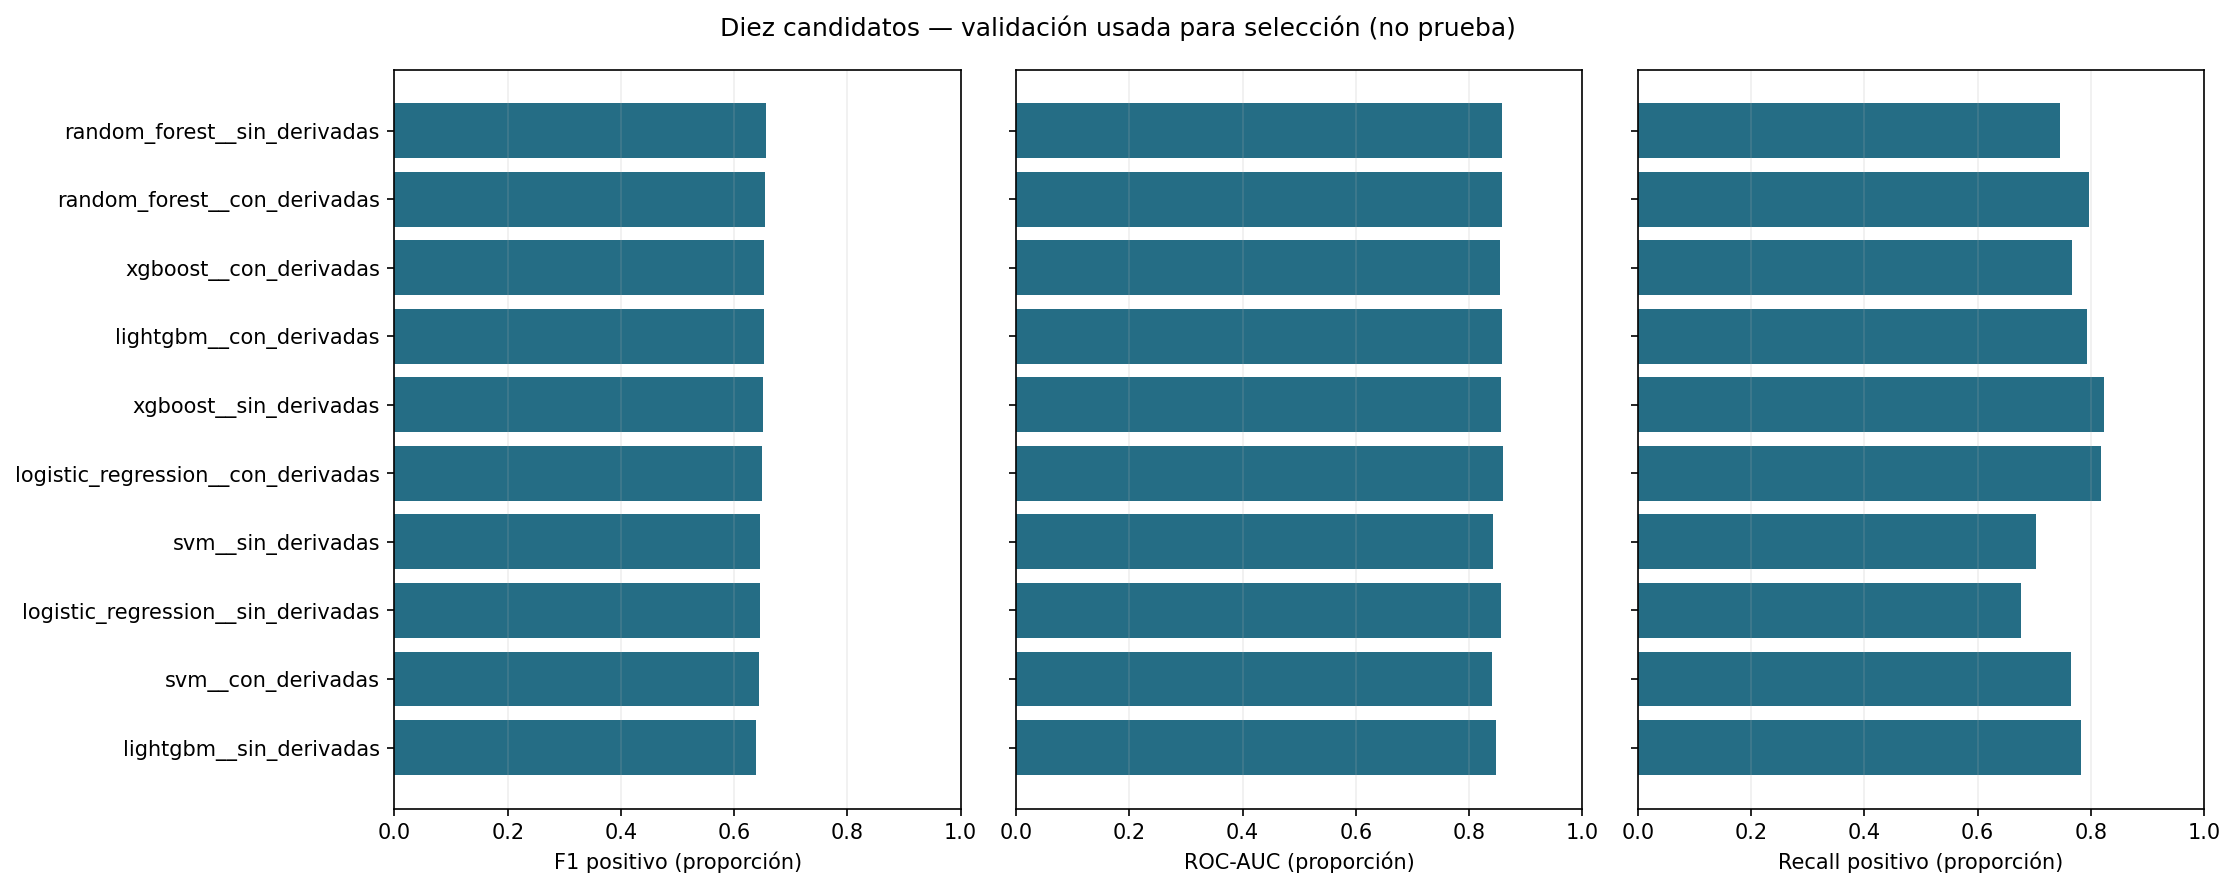

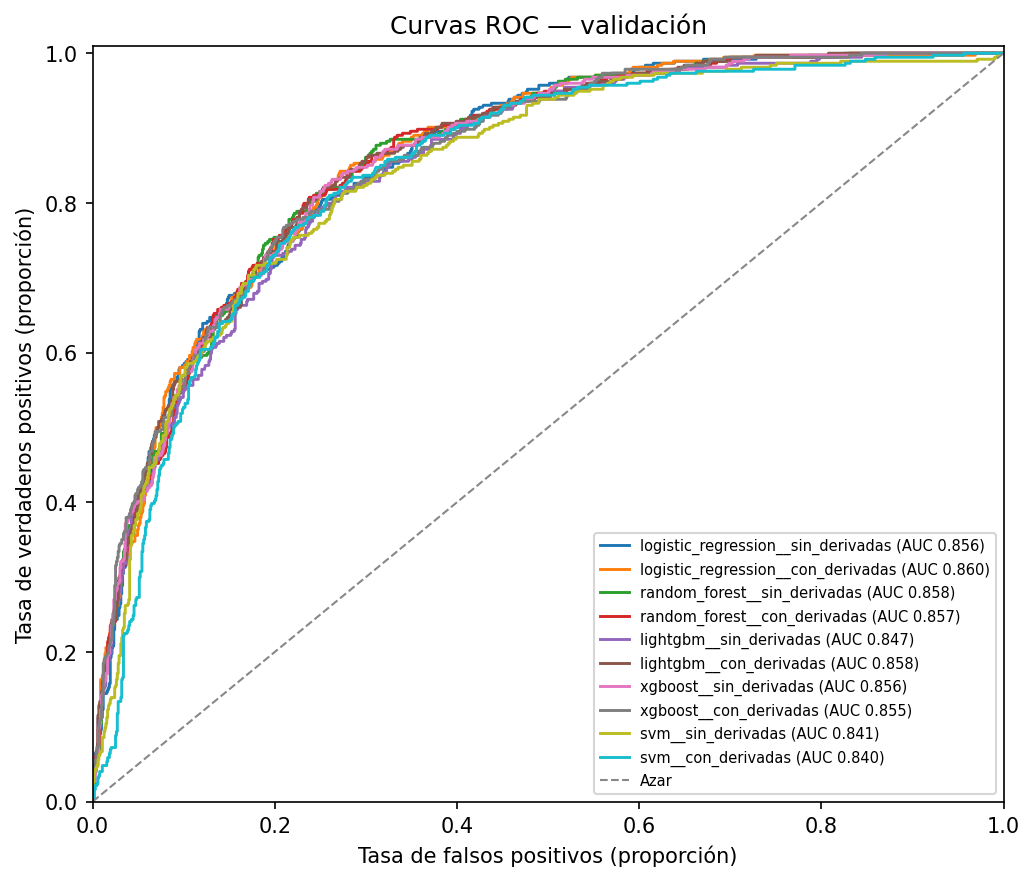

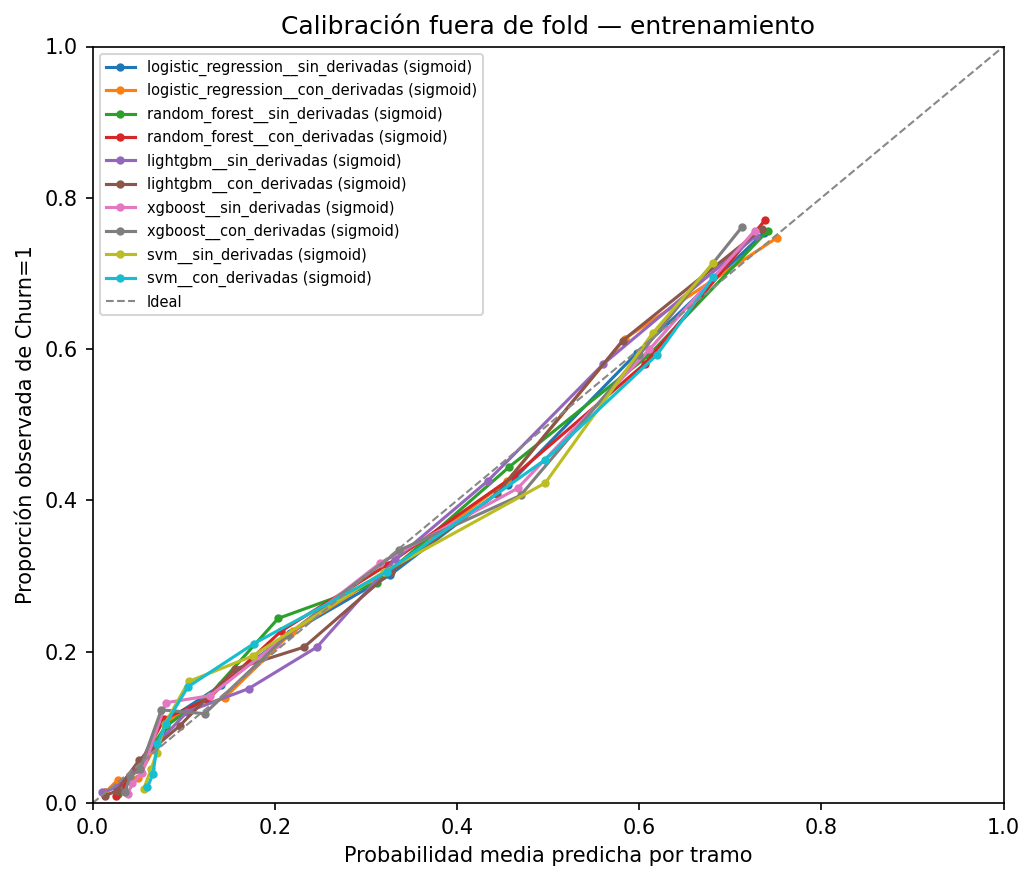

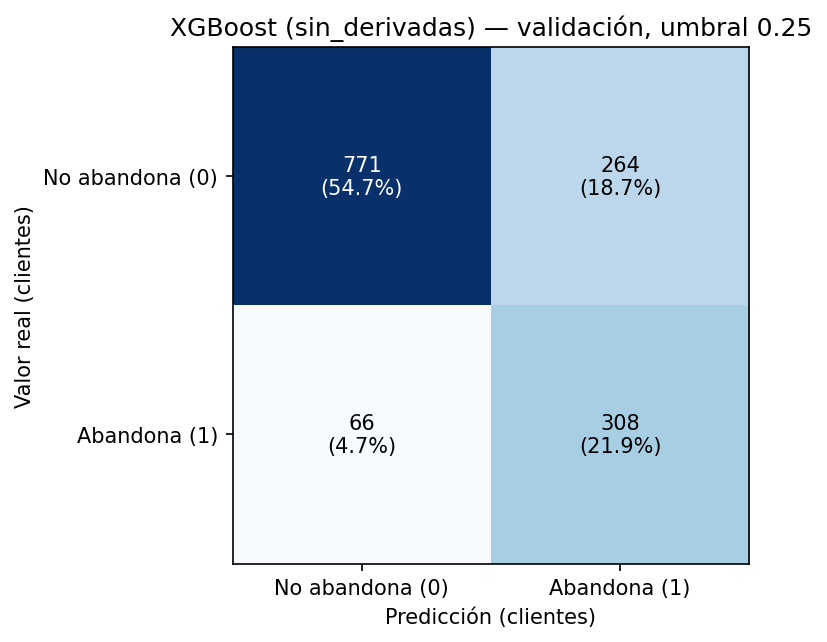

Las curvas comparativas y OOF proceden de la reproducción. La tabla y la selección se contrastaron con los reportes originales.

In [6]:
for step in meta["selection_trace"]:
    print(step)
verification = generate_frozen_reports(resources)
assert verification["validation_reproduced"] and not verification["test_reevaluated"]
for filename, directory in (
    ("comparacion_validacion.png", EVALUATION_REPORT_DIR),
    ("roc_validacion.png", REPRODUCTION_DIR / "figures"),
    ("calibracion_entrenamiento_oof.png", REPRODUCTION_DIR / "figures"),
    ("matriz_validacion_ganador.png", REPRODUCTION_DIR / "figures"),
):
    display(Image(filename=str(directory / filename)))
display(
    Markdown(
        "Las curvas comparativas y OOF proceden de la reproducción. "
        "La tabla y la selección se contrastaron con los reportes originales."
    )
)

## Prueba final ya realizada

Las cifras siguientes se leen del CSV original, cuya huella coincide con la del
manifiesto. **No se llama a `run_final`, no se predice sobre prueba y no se reajusta
el modelo.** Se dibuja su matriz a partir de los conteos guardados. Las probabilidades
originales de prueba no están disponibles: no se reconstruye una curva ROC desde AUC.

,accuracy,precision,recall,f1,roc_auc,average_precision,decision_threshold,brier,log_loss,rows,positives,model_name,model_sha256,true_negatives,false_positives,false_negatives,true_positives
0,0.741661,0.508475,0.802139,0.622407,0.829704,0.622959,0.25,0.142394,0.435869,1409,374,xgboost__sin_derivadas,0bb0a8542c14f3e23e2fd779fc8b3dd2c488c6c28db069...,745,290,74,300


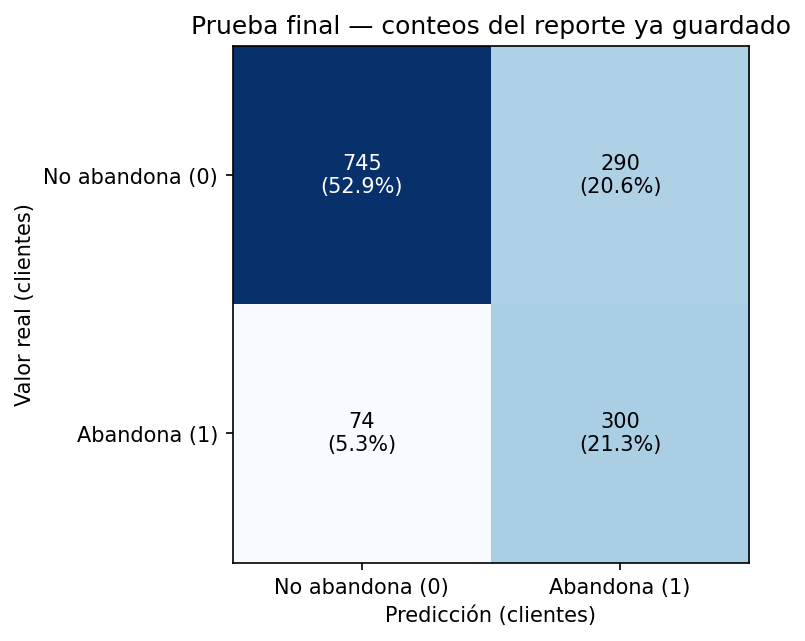

De 374 abandonos históricos se detectaron 300; quedaron 74 sin detectar. Hubo 290 falsos positivos: contactos potencialmente innecesarios si se utilizara la decisión binaria para una campaña.

- Las bandas 0.35/0.65 son convenciones operativas, no umbrales optimizados.
- SHAP describe el modelo; las coaliciones pueden romper dependencias entre servicios.
- El coste SHAP medido en esta máquina no garantiza tiempos de la web.
- No se dispone de probabilidades originales de prueba para reconstruir su curva ROC.
- Los archivos originales de CV no se recuperaron; la reproducción se entrega aparte.


In [7]:
final = resources.final_report.iloc[0]
display(resources.final_report.round(6))
display(Image(filename=str(EVALUATION_REPORT_DIR / "matriz_prueba_final_guardada.png")))
display(
    Markdown(
        f"De {int(final['positives'])} abandonos históricos se detectaron "
        f"{int(final['true_positives'])}; quedaron {int(final['false_negatives'])} sin detectar. "
        f"Hubo {int(final['false_positives'])} falsos positivos: contactos potencialmente "
        "innecesarios si se utilizara la decisión binaria para una campaña."
    )
)
assert dataset_sha256(MODEL_PATH) == frozen_hash
for limitation in verification["limitations"]:
    print("-", limitation)

## Alcance de la entrega

Las bandas Bajo/Medio/Alto (0,35/0,65) siguen siendo convenciones operativas,
distintas del umbral binario 0,25. No se inventaron costes ni una optimización
comercial de bandas. El dataset no valida horizontes futuros ni eficacia de retención.
Los archivos originales de búsqueda faltan; la reproducción coincide numéricamente
con la comparación guardada, pero no acredita por sí sola todo el historial original.

El frente 3 conserva interfaz web, recomendaciones, aceptación, informe final y despliegue.